# I - Introduction

Les déplacements forcés de populations constituent l'un des enjeux géopolitiques et humanitaires majeurs du XXIe siècle. Selon les données du Haut-Commissariat des Nations Unies pour les réfugiés (UNHCR), des millions de personnes sont contraintes chaque année de quitter leur pays d'origine en raison de conflits armés, de persécutions ou d'instabilités politiques. Parmi les grandes régions émettrices mondiales, l'Asie du Sud occupe une place singulière : marquée par des crises prolongées — notamment en Afghanistan, au Pakistan ou encore au Sri Lanka — et par l'exode massif des Rohingyas à partir de 2017, cette région combine à la fois un volume très élevé de demandeurs d'asile et une forte diversité de pays de destination à travers le monde.

Au-delà de l'urgence humanitaire, la répartition géographique de ces flux soulève d'importantes questions économiques et institutionnelles quant aux mécanismes qui gouvernent le choix d'un pays d'accueil. Si les modèles de gravité appliqués aux migrations mettent traditionnellement en avant le rôle central de la proximité géographique et des coûts de transport, les trajectoires des demandeurs d'asile répondent également à des logiques plus complexes : attractivité économique des pays de destination, présence d'un cadre juridique d'asile structuré, proximité culturelle ou linguistique, et liens historiques. L'étude de la période **2017–2020** offre à cet égard un cadre d'observation privilégié : elle permet d'analyser ces déterminants structurels sur quatre années consécutives, avant les bouleversements majeurs induits par les restrictions de mobilité liées à la crise sanitaire puis par les ruptures géopolitiques de 2021.

Ainsi, nous pouvons nous poser la question suivante : **quels sont les facteurs géographiques, économiques et culturels qui déterminent le choix du pays de destination des demandeurs d'asile originaires d'Asie du Sud ?** Plus précisément, la proximité géographique et la richesse du pays d'accueil suffisent-elles à expliquer l'orientation des flux, ou d'autres variables — telles que le partage d'une frontière, d'une langue commune ou de liens coloniaux — jouent-elles un rôle déterminant ?

Ici, nous considérerons que les mouvements migratoires étudiés correspondent aux **nouvelles demandes d'asile** enregistrées annuellement par l'UNHCR entre 2017 et 2020. De plus, nous mesurerons le choix d'une destination par la **part des demandes d'asile** d'un pays d'origine qui s'y dirige (`destination_share`), et nous évaluerons l'influence des facteurs explicatifs en croisant ces flux avec les variables bilatérales de la base *CEPII Gravity* (distance pondérée entre pays, PIB par habitant, contiguïté géographique, langue officielle commune, proximité religieuse et passé colonial).


### Sommaire

- **I. Données et préparation de la base**
    - A. Les données UNHCR
    - B. Les données CEPII Gravity
    - C. Jointure, nettoyage des doublons et construction de `destination_share`
    - D. Limites sur les données

- **II. Vue macroscopique et focus sur l'Asie du Sud**
    - A. Vue macro : volume de demandes d'asile et diversité des destinations par région
        - _1. Statistiques descriptives globales_
        - _2. Comparaison interrégionale et justification du choix de l'Asie du Sud_
    - B. Focus sur l'Asie du Sud
        - _1. Cartographie mondiale des principaux flux migratoires (2017-2020)_
        - _2. Volume et diversité des destinations pour les 9 pays de la région_
        - _3. Principales destinations par pays d'origine (`destination_shares`)_

- **III. Étude des facteurs déterminant le choix de destination**
    - A. Richesse du pays d'accueil (`gdpcap_d`) : les destinations les plus riches reçoivent-elles davantage de flux ?
    - B. Distance géographique (`distw_harmonic`) : les destinations les plus proches reçoivent-elles davantage de flux ?
        - _1. Régression linéaire simple sur les variables brutes_
        - _2. Passage au modèle log-log_
        - _3. Interprétation économique et limites méthodologiques_
    - C. Proximité linguistique et facteurs culturels ou frontaliers
        - _1. Langue officielle commune (`comlang_off`)_
        - _2. Proximité religieuse (`comrelig`), effet frontière (`contig`) et liens coloniaux (`col_dep_ever`)_
    - D. Synthèse et mise en perspective avec la littérature

- **Conclusion**

# I - Données

## A. Les données UNHCR

L'Agence des Nations Unies pour les réfugiés (UNHCR) met à disposition plusieurs bases de données relatives aux déplacements forcés de population.
Dans le cadre de cette étude, une première source de données est récupérée à partir de l'API de l'UNHCR. L'endpoint consacré aux pays permet notamment d'obtenir les informations suivantes :
- le nom du pays ;
- son code ISO alpha-3, norme internationale permettant d'identifier chaque pays ;
- la région du monde à laquelle il appartient.

Une seconde source de données de l'UNHCR, disponible sous la forme d'un fichier Excel, est utilisée pour mesurer les déplacements entre pays. Elle contient des observations par pays d'origine, pays de destination et année.
Les variables retenues sont :
- le pays d'origine et son code ISO ;
- le pays de destination et son code ISO ;
- l'année ;
- le type de population ou de mouvement (PT) ;
- le nombre d'observations correspondant (Count).

L'objectif de l'étude étant d'analyser la répartition géographique des nouvelles demandes d'asile, seules les observations pour lesquelles PT = ASY sont conservées. Dès lors, la variable Count correspond au nombre de nouvelles demandes d'asile enregistrées pour un pays d'origine, un pays de destination et une année donnés.
Aussi, la variable Count ne doit pas être interprétée comme un nombre d'individus uniques : une même personne peut déposer une demande d'asile dans plusieurs pays au cours de son parcours. L'analyse porte donc sur la distribution des nouvelles demandes d'asile entre pays de destination, et non sur des choix individuels uniques.

Les données sont ensuite nettoyées afin d'homogénéiser les types des différentes variables, et seules les observations comprises entre 2017 et 2020 sont conservées.
Enfin, les informations géographiques obtenues via l'API sont jointes aux données relatives aux demandes d'asile grâce aux codes ISO des pays. Cette étape permet notamment d'associer à chaque pays d'origine sa région du monde.
On obtient ainsi le jeu de données `unhcr_df`, qui constitue la base UNHCR utilisée pour la suite de l'analyse.

## B. Les données CEPII Gravity

Le Centre d’études prospectives et d’informations internationales (CEPII) est un organisme de recherche indépendant français étudiant l’économie internationale. Il a mis à disposition diverses bases de données, et notamment la database gravity, qui recense pour chaque paire de pays et chaque année entre 1948 et 2020 diverses informations utiles pour étudier leurs relations économiques. Nous avons utilisé les variables suivantes dans notre analyse:

- l’année de l’observation ;
- les codes ISO3 des deux pays étudiés ;
- les PIB par habitants des pays étudiés ;
- la distance harmonique pondérée entre les deux pays.

Après conservation des observations entre 2017 et 2020, nettoyage des données et harmonisation des noms et types de variables entre les bases, nous avons joint la database unhcr_df et les données provenant de gravity pour former la database south_asia, utilisée pour la suite de l’analyse. 


In [29]:
# Collecte et manipulation de données
import requests
import numpy as np
import pandas as pd

# Cartographie et visualisation
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrowPatch
import plotly.express as px

# Modélisation
from sklearn.linear_model import LinearRegression

# Récupération des fonctions

from plots import (plot_carte_flux,plot_regression_distance_simple,plot_regression_distance_log)
from analyse import (charger_south_asia,charger_destination_shares,scatter_plot_pib_demandes_asile,scatter_plot_ech_log,reg_lin_log_log)

south_asia = charger_south_asia()
print(south_asia)


(1427, 6)
(1780, 13)
     coo_iso     coo_name coa_iso                  coa_name  year  refugees  \
0        AFG  Afghanistan     ALB                   Albania  2017        29   
2        AFG  Afghanistan     ARG                 Argentina  2017         7   
3        AFG  Afghanistan     ARM                   Armenia  2017         5   
4        AFG  Afghanistan     AUS                 Australia  2017      1478   
5        AFG  Afghanistan     AUT                   Austria  2017      3525   
...      ...          ...     ...                       ...   ...       ...   
1773     PAK     Pakistan     THA                  Thailand  2020        67   
1775     PAK     Pakistan     UGA                    Uganda  2020        14   
1777     PAK     Pakistan     UKR                   Ukraine  2020         5   
1779     PAK     Pakistan     USA  United States of America  2020      1008   
1757     PAK     Pakistan     ZAF              South Africa  2020        38   

      distw_harmonic contig co

# II. Vue macroscopique et focus sur l'Asie du Sud

## B. Focus sur l'Asie du Sud_
### 1. Cartographie mondiale des principaux flux migratoires (2017-2020)_



In [20]:
#plot_carte_flux(south_asia)


# IV. Analyse des données

## A. Lien entre la distance géographique et le choix de destination

Afin d'évaluer l'influence de l'éloignement géographique sur la répartition des demandeurs d'asile originaires d'Asie du Sud entre 2017 et 2020 , nous nous servons du DataFrame south_asia et plus particulièrement des données “distw_harmonic” et “destination_share”. Le premier, partant de deux pays i et j et pour une année t donnée, donne le calcul de la moyenne harmonique des distances entre les principales agglomérations des deux pays, pondérée par le poids démographique respectif de chaque ville dans la population totale du pays. Le deuxième mesure la proportion des nouvelles demandes d'asile en provenance du pays i qui ont été déposées dans le pays j. Cet indicateur est filtré sur les nouvelles demandes d’asile (PT = = “ASY”).

### 1. Régression linéaire simple sur les variables brutes 

Dans un premier temps, nous estimons par les moindres carrés ordinaires le modèle linéaire suivant : 

destination_shareijt=0+1distw_harmonicij+ijt

L'estimation aboutit aux paramètres suivants :
Constante (0) : 0,0096 (soit une part prédite de 0.96 %  à distance nulle) ;
Pente (1) : +2,4310-6 ;
Coefficient de détermination (R2) : 0,0102 (soit 1.02 % de la variance expliquée).
Graphiquement, on obtient :

In [21]:
plot_regression_distance_simple(south_asia)


TypeError: 'NoneType' object is not subscriptable

On remarque alors que la majorité de la distribution est écrasée près de l’axe des abscisses (0 % de demandeurs d’asyle) tandis que quelques pays captent entre 20% et 100% des demandes. De plus, il est intéressant de noter que ces pics peuvent apparaître à courte (100 km) comme à longue distance ( 12500 km). Néanmoins avec un R2 de 1.02 %, la droite de régression reste presque horizontale et ne permet pas de donner un lien favorable entre distance et choix de destination. Pour ne pas avoir de données trop écrasées, il est intéressant de passer à une régression du type log-log.

### 2. Passage au modèle log-log 
Pour corriger l'écrasement des échelles, nous appliquons une transformation logarithmique aux deux variables :

(destination_shareijt)=0+1(distw_harmonicij)+ijt
Les résultats de cette seconde estimation sont les suivants :
Constante (0) : -8,761 ;
Pente / Élasticité (1) : +0,313 ;
Coefficient de détermination (R2) : 0,0075 (soit 0.75 % de la variance expliquée).


In [ ]:
plot_regression_distance_log(south_asia)

Cette fois-ci, bien que le passage au logarithme permette d'étaler le nuage de points sur l'ensemble du plan, la qualité d'ajustement demeure très faible (R2 < 1%) et la pente estimée reste légèrement positive (+0,313).
Il est tout de même intéressant de noter que cette estimation repose sur tous les couples origine-destination ayant enregistré au moins une nouvelle demande d'asile entre 2017 et 2020 (refugees>0), une condition nécessaire à l'utilisation de la transformation logarithmique. Ce choix méthodologique écarte les pays n'accueillant aucun ressortissant d'Asie du Sud, dont l'inclusion tirerait mécaniquement la droite de régression vers l'axe horizontal Néanmoins, notre démarche ne vise pas à expliquer la probabilité d'ouverture d'un couloir migratoire, mais à comparer l'attractivité relative des pays qui constituent effectivement des destinations d'asile pour la région. L'étude mesure ainsi comment la distance géographique répartit les flux parmi les pays d'accueil réellement sollicités par les demandeurs d'asile.


### 3.Interprétation  

Contrairement à l’intuition standard qui nous dirait que la distance est un frein à l’immigration (notamment en raison de coûts de transports plus élevés et du changement de type de transports (avions, bâteau au lieu de la marche ou de la voiture),nos estimations ne font pas ressortir de relation négative entre éloignement et part des demandes d'asile. Ceci peut s’expliquer par différentes raisons : 
La spécificité d’une demande d’asile l'étude porte exclusivement sur les nouvelles demandes d'asile enregistrées et non sur les stocks globaux de réfugiés. Or, si les pays frontaliers d'Asie du Sud accueillent d'importants volumes de réfugiés sous d'autres statuts, les demandes d'asile individuelles formelles se dirigent massivement vers les pays occidentaux dotés de systèmes d'asile structurés, notamment l'Europe de l'Ouest et l’Amérique du Nord
L’absence de pondération par la taille des flux d’origine : dans la régression, chaque observation reçoit le même poids, ainsi certains pays d’origine qui enregistrent des demandes d'asiles concentrées sur peu de pays, de plus lointains ( comme Maldives avec États-Unis) tirent mécaniquement la droite de régression vers le haut.
Ainsi, la distance géographique seule ne détermine pas le choix des demandeurs d’asile, à distance comparable il faut s’intéresser à d’autres facteurs ( PIB du pays (gdpcap_d), proximité languistique ou histoire colonial) pour comprendre le choix du pays de refuge.


## B. Lien entre la richesse du pays d'accueil (`gdpcap_d`) et le nombre de demandes d'asile.
Afin d'évaluer l'influence du PIB la répartition des demandeurs d'asile originaires d'Asie du Sud entre 2017 et 2020 , nous nous servons du DataFrame south_asia et plus particulièrement des données “gdp” et “refugees_sum”. La première donnée correspond à la moyenne du PIB par habitant d’un pays sur la periode 2017-2020 (en milliers de US$), et la deuxième correspond au nombre de demandes d’asile reçues par un pays en provenance de l’Asie du Sud durant la periode 2017-2020. Il y a donc un point par pays de destination. Nous obtenons ce graphique:


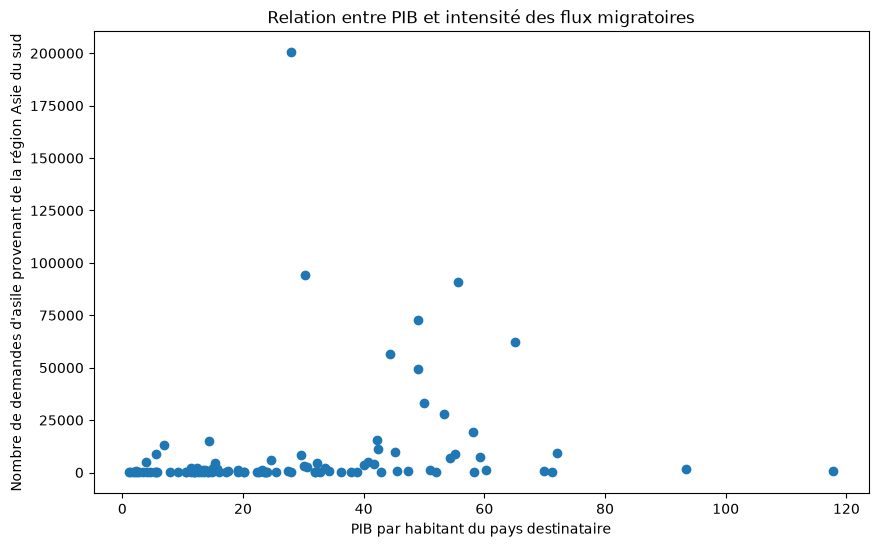

In [30]:
scatter_plot_pib_demandes_asile(south_asia)

Nous obtenons une distribution écrasée près de l’axe des abscisses, avec quelques pics, situés entre 25 et 70 milliers de dollars par habitant. Afin d’obtenir un graphe plus lisible, il est intéressant de passer à une échelle logarithmique:

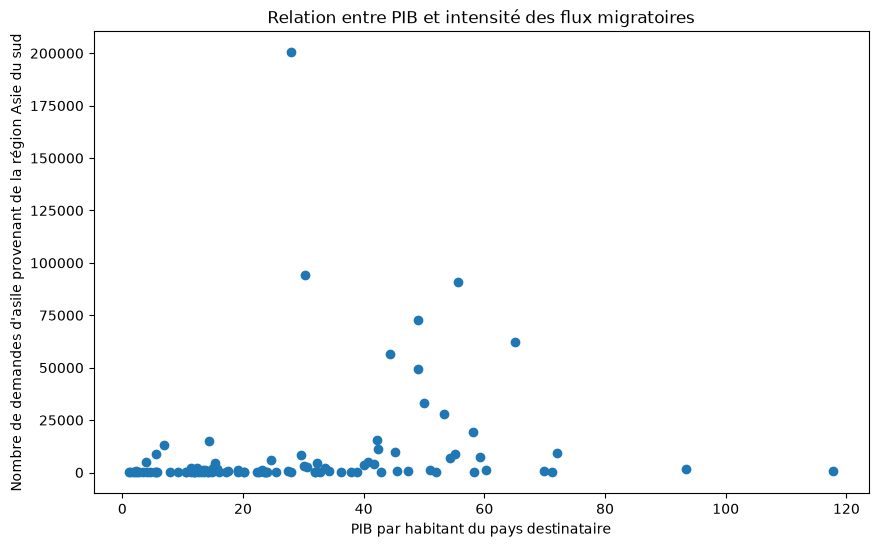

In [31]:
scatter_plot_ech_log(south_asia)

Ainsi, on semble observer une corrélation positive entre le PIB et le nombre de demandes d’asile. 
Afin d’obtenir une analyse plus précise de la situation, on réalise une régression linéaire sur les deux variables. On estime donc par les moindres carrés ordinaires le modèle suivant:

(refugees_sum)= c0+c1(gdp)+residu.

L'estimation aboutit aux paramètres suivants :

- Constante (c0) : 2.70638342  ;
- Pente / Élasticité (c1) : 1.19027949  ;
- Coefficient de détermination (R2) : 0.22363344458182455  (soit 22 % de la variance expliquée). Le pouvoir explicatif du modèle semble donc élevé.


Modèle log-log - Constante : [2.70638342]
Modèle log - Pente : [1.19027949]
Modèle log - R² : 0.22363344458182455


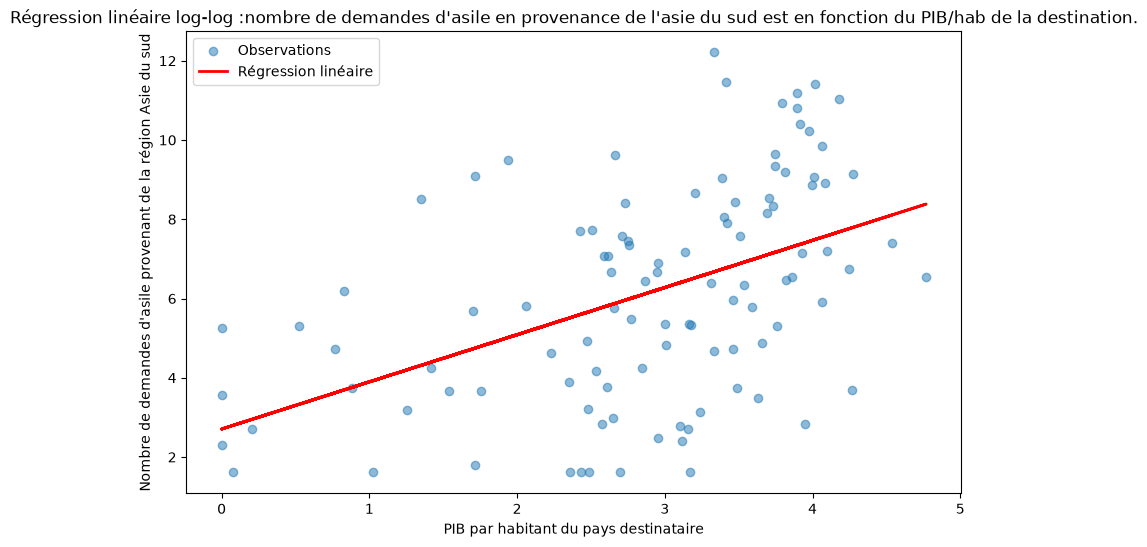

In [32]:
reg_lin_log_log(south_asia)

Ainsi, le modèle renforce l’hypothèse d’une corrélation positive entre le PIB par habitant et le nombre de demandes d’asile.

#### Interpretation:
Cette relation positive entre le nombre de demandes d’asile et le PIB/hab paraît intuitive. En effet, les pays ayant un fort PIB/hab offrent des meilleures conditions de vie et sont donc plus attractifs pour les réfugiés. De plus, les pays développés peuvent posséder des systèmes d’asile plus structurés, et accueillent donc plus de demandes d’asile individuelles formelles.
